In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/0
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第0章 OSって個人で作れるの？ — 0.1 OSの作り方 (*How to Build an OS*)

---

## 1. 導入：なぜ今「OSをゼロから自作する」のか？

現代のソフトウェア開発環境では、高機能な Web サービスや VR ゲーム、IoT デバイスの制御プログラムまで、フレームワークやライブラリを組み合わせることで個人でも驚くほど簡単に作れるようになりました。コンパイラや CPU の自作解説書も多く出版されています。

しかし、**オペレーティングシステム (*Operating System: OS*)** に関しては、むしろ「個人でゼロから作りにくい時代」になっています。その理由は、ハードウェアの高度化（64ビット化、UEFI、USB 3.0、マルチコア、高度なメモリ保護）に伴って OS 自体が巨大化・複雑化し、ブラックボックスの奥深くに隠れてしまったからです。

本シリーズで構築する **MikanOS** は、2006年の名著『30日でできる！OS自作入門』（川合秀実 著、通称「はりぼてOS」本）の「小さく作ってすぐ動かす」精神を受け継ぎつつ、**現代のPCアーキテクチャ（UEFI BIOS、Intel 64 モード、ページング、USB 3.0 ドライバ、マルチウィンドウ GUI、プリエンプティブ・マルチタスク、ファイルシステム）** に完全対応した C++ 製自作 OS です。

---

### 0.1.1 商用OSの巨大化と初期・教育用OSのコード規模比較 (*Scale of Operating Systems*)

私たちが普段使っている Windows、macOS、Linux はいずれも数千万行規模の巨大なソフトウェアです。
- **Linux バージョン 4.10**（2017年リリース）：約 **2,100万行**（$2.1 \times 10^7$ LOC: *Lines of Code*）
- **Windows / macOS**：非公開だが数千万行規模

これほど巨大なソフトウェアを個人で作ることは不可能です。しかし、歴史的な商用 OS も最初から巨大だったわけではありません。

| OS 名称 | リリース年 | コード行数 (LOC) | ターゲット仕様 | 備考 |
| :--- | :---: | :---: | :--- | :--- |
| **はりぼてOS** (*Haribote OS*) | 2006年 | **4,249 行** | x86 (32-bit, レガシーBIOS) | バイナリ約40KB、フロッピー起動 |
| **Linux 0.01** | 1991年 | **10,239 行** | x86 (32-bit, Intel 80386) | リーナス・トーバルズ氏による初期版 |
| **MikanOS** (最終カーネル本体) | 2021年 | **11,071 行** | **x86-64 (64-bit, UEFI)** | GUI・USB3.0・マルチタスク・FAT完備 |
| **Linux 4.10** | 2017年 | **約21,000,000 行** | マルチアーキテクチャ | 現代の巨大モノリシックカーネル |

#### 数理的スケール評価
MikanOS の最終的な OS 本体行数 $L_{\text{Mikan}} = 11,071$ 行を、Linux 0.01 の行数 $L_{\text{Linux0.01}} = 10,239$ 行および Linux 4.10 の行数 $L_{\text{Linux4.10}} = 2.1 \times 10^7$ 行と比較すると、以下の比率になります。

$$
R_{\text{init}} = \frac{L_{\text{Mikan}}}{L_{\text{Linux0.01}}} = \frac{11,071}{10,239} \approx 1.081 \quad (\text{約 } 1.08 \text{ 倍})
$$

$$
R_{\text{modern}} = \frac{L_{\text{Linux4.10}}}{L_{\text{Mikan}}} = \frac{21,000,000}{11,071} \approx 1,896.85 \quad (\text{約 } 1,900 \text{ 分の } 1)
$$

また、全30日（第1章〜第30章）のカリキュラムで割ると、1日（1章）あたりの平均コード増加量 $\bar{L}_{\text{day}}$ は次のように導出されます。

$$
\bar{L}_{\text{day}} = \frac{L_{\text{Mikan}}}{30} = \frac{11,071}{30} \approx 369.03 \text{ [lines/day]}
$$

つまり、**「1章あたり平均370行程度の C++ コードを積み上げていくだけで、初期の Linux 0.01 と同規模の、GUI とマルチタスクを備えた 64ビット OS が個人で完全に作れてしまう」** のです。


In [2]:
# C++20 による OS コード規模の定量比較・検証プログラムのコンパイルと実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
cpp_source = repo_root / "src" / "ch00" / "os_scale_analyzer.cpp"
bin_dir = repo_root / "bin"
bin_dir.mkdir(exist_ok=True)
bin_path = bin_dir / "ch00_os_scale_analyzer"

compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic", str(cpp_source), "-o", str(bin_path)]
subprocess.run(compile_cmd, check=True)

result = subprocess.run([str(bin_path)], capture_output=True, text=True, check=True)
print(result.stdout)


=== Section 0.1: OS Codebase Scale Analysis (C++20) ===
Haribote OS (30-day OS)    | Year: 2006 | LOC:       4249 | 64-bit: No  | UEFI: No 
Linux 0.01                 | Year: 1991 | LOC:      10239 | 64-bit: No  | UEFI: No 
MikanOS (Final Kernel)     | Year: 2021 | LOC:      11071 | 64-bit: Yes | UEFI: Yes
Linux 4.10                 | Year: 2017 | LOC:   21000000 | 64-bit: Yes | UEFI: Yes

[Analysis]
- MikanOS / Haribote ratio   : 2.61x
- MikanOS / Linux 0.01 ratio : 1.08x
- Linux 4.10 / MikanOS ratio : 1896.85x
- MikanOS average LOC / day  : 369.03 lines/day (over 30 days)



---

### 0.1.2 OSを作る2つのアプローチ：既存OSの改造 vs フルスクラッチ自作

「OSを作る」と言ったとき、大きく分けて **2通りの作り方** があります。

```mermaid
flowchart TD
    Root["OSを作るアプローチ (How to Build an OS)"]
    Root --> Mod["アプローチ A: 既存OSの改造\n(Modification / Derivation)"]
    Root --> Scratch["アプローチ B: 全部自分で作る (フルスクラッチ)\n(From Scratch / MikanOS Approach)"]

    Mod --> ModEx["例: Linux派生ディストリビューション,\nAndroid (Linux Kernel基盤),\nmacOS / iOS (Darwin / XNU基盤)"]
    ModEx --> ModPros["メリット: 実用的なOSが最速で作れる\nデメリット: OS全体を見渡せず、ごく一部しか体験できない"]

    Scratch --> ScratchFlow["電源ON → UEFIブートローダ → カーネル起動\n→ メモリ/割り込み/USBドライバ → GUI/マルチタスク → アプリ実行"]
    ScratchFlow --> ScratchPros["メリット: ブラックボックスゼロ！\nPCとOSの全レイヤが繋がる感動を体験できる"]
```

1. **既存の OS を改造する方法 (*Modifying an Existing OS*)**:
   - Linux カーネルなどをベースにして、必要な機能を追加し、不要な機能を取り除くアプローチです。
   - **macOS**（Mach + FreeBSD ベースの XNU カーネル）や **Android**（Linux カーネルベース）も、広義にはこのアプローチで開発されています。
   - **特徴**: 実用的な OS を作るには最短の道ですが、巨大なコードベースのほんの一部しか触れないため、「OS の全体像を見渡す」ことは困難です。
2. **全部自分で作る方法 (*Building from Scratch*)**:
   - PC の電源を入れて UEFI BIOS からブートローダを呼び出すところから、ピクセル描画、マウス・キーボード制御、マルチタスク、アプリ実行まで **すべてをゼロから自分の手で書く** アプローチです。
   - **特徴**: 本書（MikanOS）が採用する方法です。1万行強のコンパクトなサイズだからこそ、**OS の隅々まで自分の頭で把握し、ブラックボックスを完全に解き明かす**ことができます。


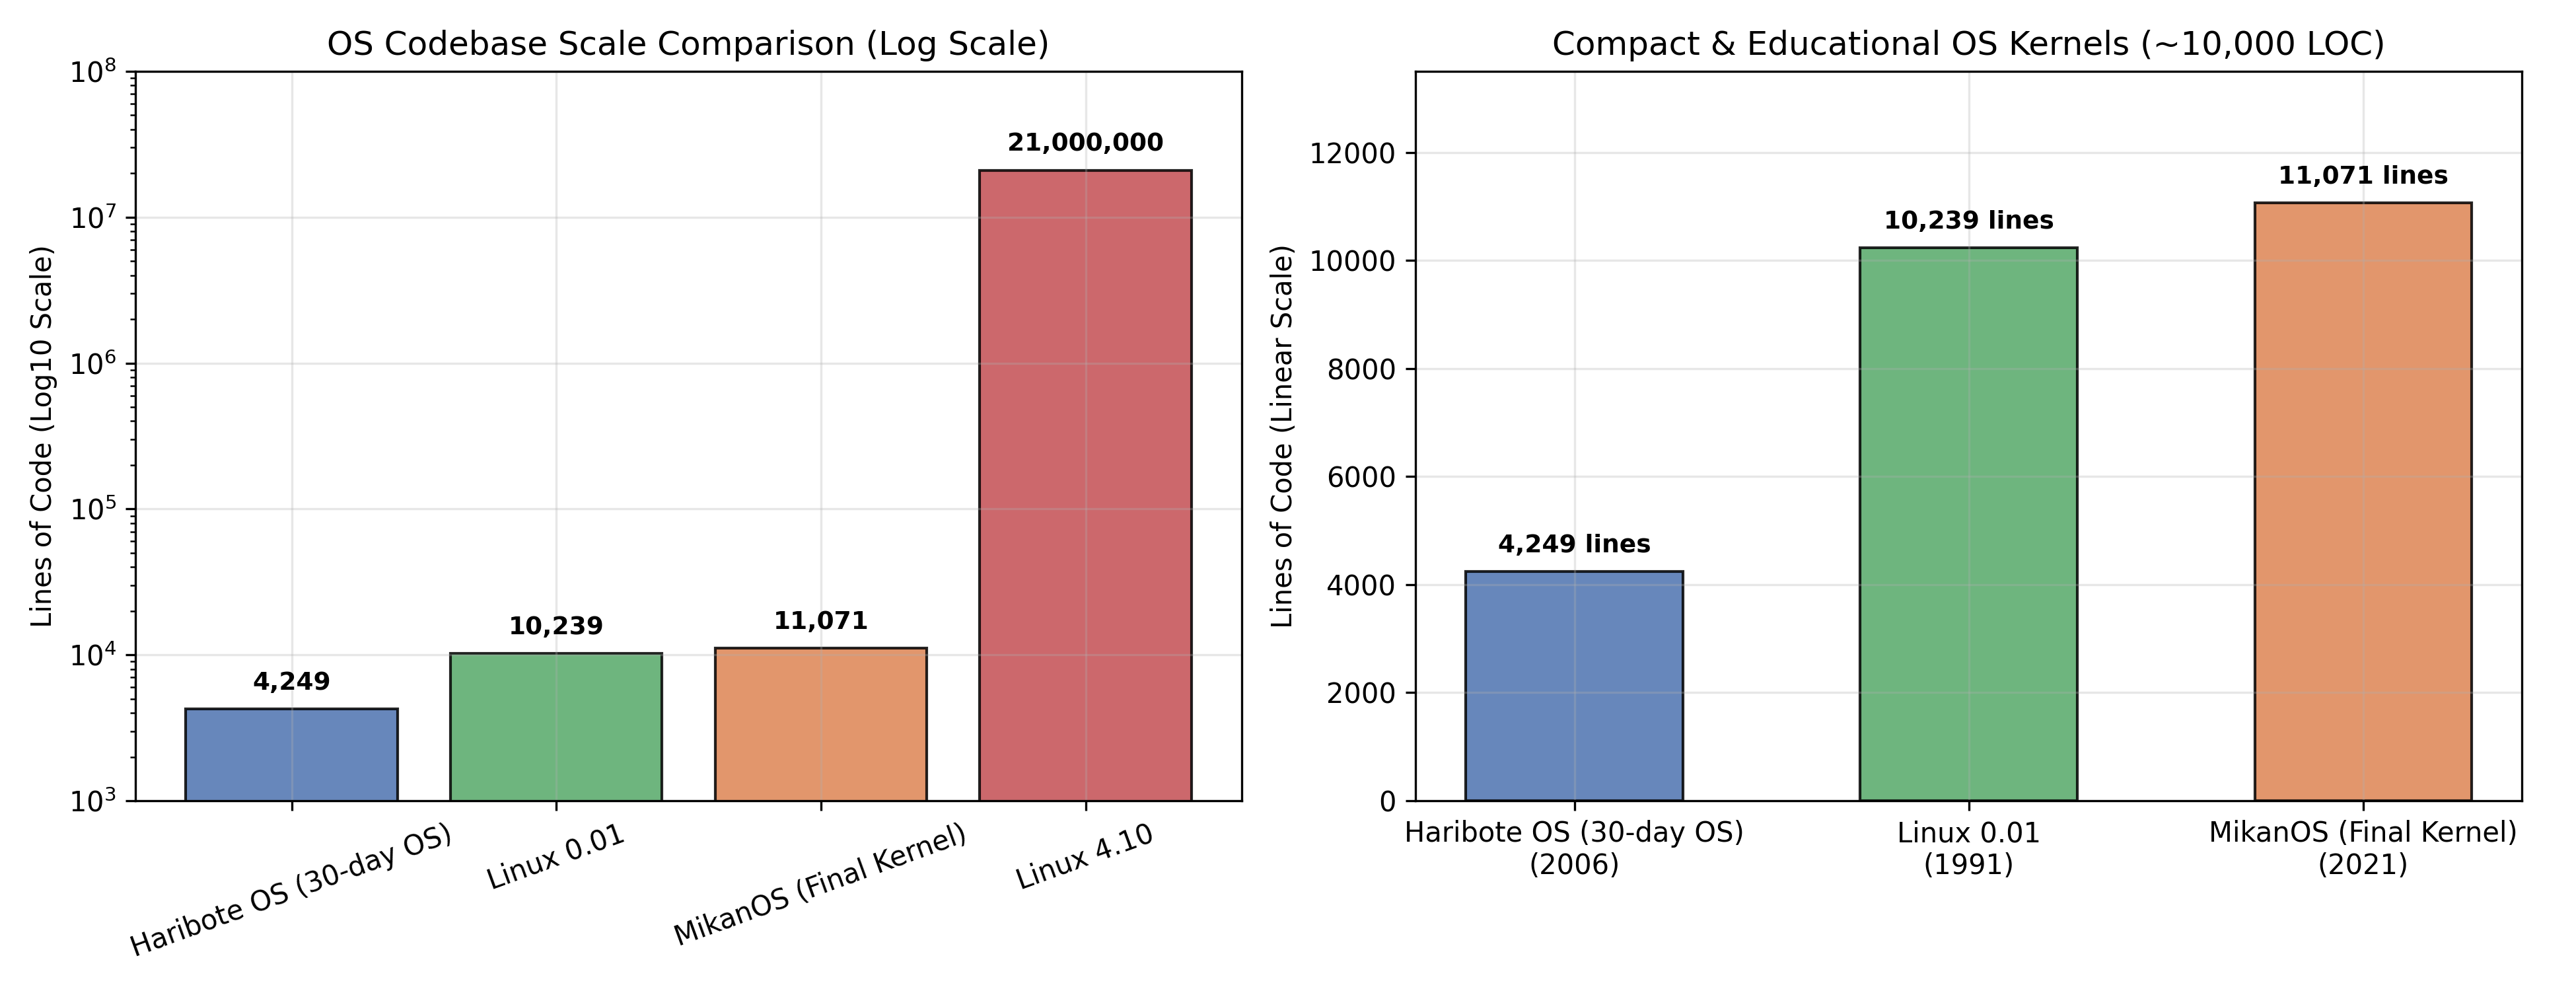

In [3]:
# 図版生成 1: 歴史的・教育用OSと現代Linuxのコード規模比較 (対数スケール & 線形スケール)
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from common import HISTORICAL_OS_METRICS, setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)

names = [m.name for m in HISTORICAL_OS_METRICS]
locs = [m.lines_of_code for m in HISTORICAL_OS_METRICS]
years = [m.release_year for m in HISTORICAL_OS_METRICS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: Log10 scale comparison including Linux 4.10
colors = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
bars1 = ax1.bar(names, locs, color=colors, edgecolor="black", alpha=0.85)
ax1.set_yscale("log")
ax1.set_ylabel("Lines of Code (Log10 Scale)")
ax1.set_title("OS Codebase Scale Comparison (Log Scale)")
ax1.tick_params(axis="x", rotation=20)
for bar, loc in zip(bars1, locs):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        loc * 1.25,
        f"{loc:,}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
ax1.set_ylim(1_000, 100_000_000)

# Right: Linear scale comparison of compact / educational OS kernels
compact_metrics = HISTORICAL_OS_METRICS[:3]
c_names = [f"{m.name}\n({m.release_year})" for m in compact_metrics]
c_locs = [m.lines_of_code for m in compact_metrics]
bars2 = ax2.bar(c_names, c_locs, color=colors[:3], edgecolor="black", width=0.55, alpha=0.85)
ax2.set_ylabel("Lines of Code (Linear Scale)")
ax2.set_title("Compact & Educational OS Kernels (~10,000 LOC)")
for bar, loc in zip(bars2, c_locs):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        loc + 250,
        f"{loc:,} lines",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
ax2.set_ylim(0, 13_500)

fig.tight_layout()
out_fig1 = result_dir / "fig0_1_os_codebase_scale.png"
fig.savefig(out_fig1, dpi=300)
plt.close(fig)

display(Image(filename=str(out_fig1)))


---

### 0.1.3 カーネル設計論の壁と「段階的プロトタイピング」の思考法

いざ「OSを自作する」と言うと、周囲の詳しい人から様々な専門的質問を投げかけられることがあります。
- **モノリシックカーネル (*Monolithic Kernel*)** にするのか、**マイクロカーネル (*Microkernel*)** にするのか？
- **メモリ管理 (*Memory Management*)** のアルゴリズムはどうするのか？
- **リアルタイム性 (*Real-time Guarantee*)** は担保するのか？

```mermaid
flowchart LR
    subgraph Monolithic["モノリシックカーネル (Linux, MikanOS)"]
        direction TB
        M_App["アプリケーション (Ring 3)"]
        M_Kernel["カーネル空間 (Ring 0)\n[スケジューラ | メモリ管理 | ファイルシステム | USB/画面ドライバ]"]
        M_HW["ハードウェア (CPU / Memory / PCI / xHCI)"]
        M_App -- "システムコール" --> M_Kernel
        M_Kernel -- "直接制御" --> M_HW
    end

    subgraph Micro["マイクロカーネル (Minix, L4等)"]
        direction TB
        U_App["アプリケーション (Ring 3)"]
        U_Srv["ユーザー空間サーバ (Ring 3)\n[ファイルサーバ] [デバイスドライバ]"]
        U_Micro["最小カーネル (Ring 0)\n[IPC通信 | 最小スケジュール | アドレス空間]"]
        U_HW["ハードウェア"]
        U_App <-- "IPC (プロセス間通信)" --> U_Srv
        U_App --> U_Micro
        U_Srv --> U_Micro
        U_Micro --> U_HW
    end
```

OS の理論を学ぶこと自体は非常に重要です。しかし、著者の内田公太（uchan）氏は**「最初から完璧に作ろうとしないこと」「理論をすべて勉強してから書き始めようとしないこと」**を強く推奨しています。

> **💡 OS自作を完走するための黄金律（Incremental Prototyping）**
> 1. 最初から完璧な設計を目指すと、先人の巨大な理論に圧倒されて手が止まってしまう。
> 2. まずは **「OSっぽく見えるおもちゃ」** を作り、画面に1つ点を描く・マウスを動かすといった小さな感動を積み重ねる。
> 3. おもちゃをステップ・バイ・ステップで作り込んでいくうちに、なぜ割り込みが必要なのか、なぜページングやシステムコールが必要なのかが**実体験として腑に落ち、結果として本物のOSに近づいていく**。

実際に、公式リポジトリ（`uchan-nos/mikanos`）の各章タグ（`day02b` 〜 `day30f`）におけるカーネル＋ブートローダのコード行数とファイル数の推移を解析すると、最初から1万行を書くのではなく、最初はわずか **1ファイル・144行** からスタートしていることがわかります。


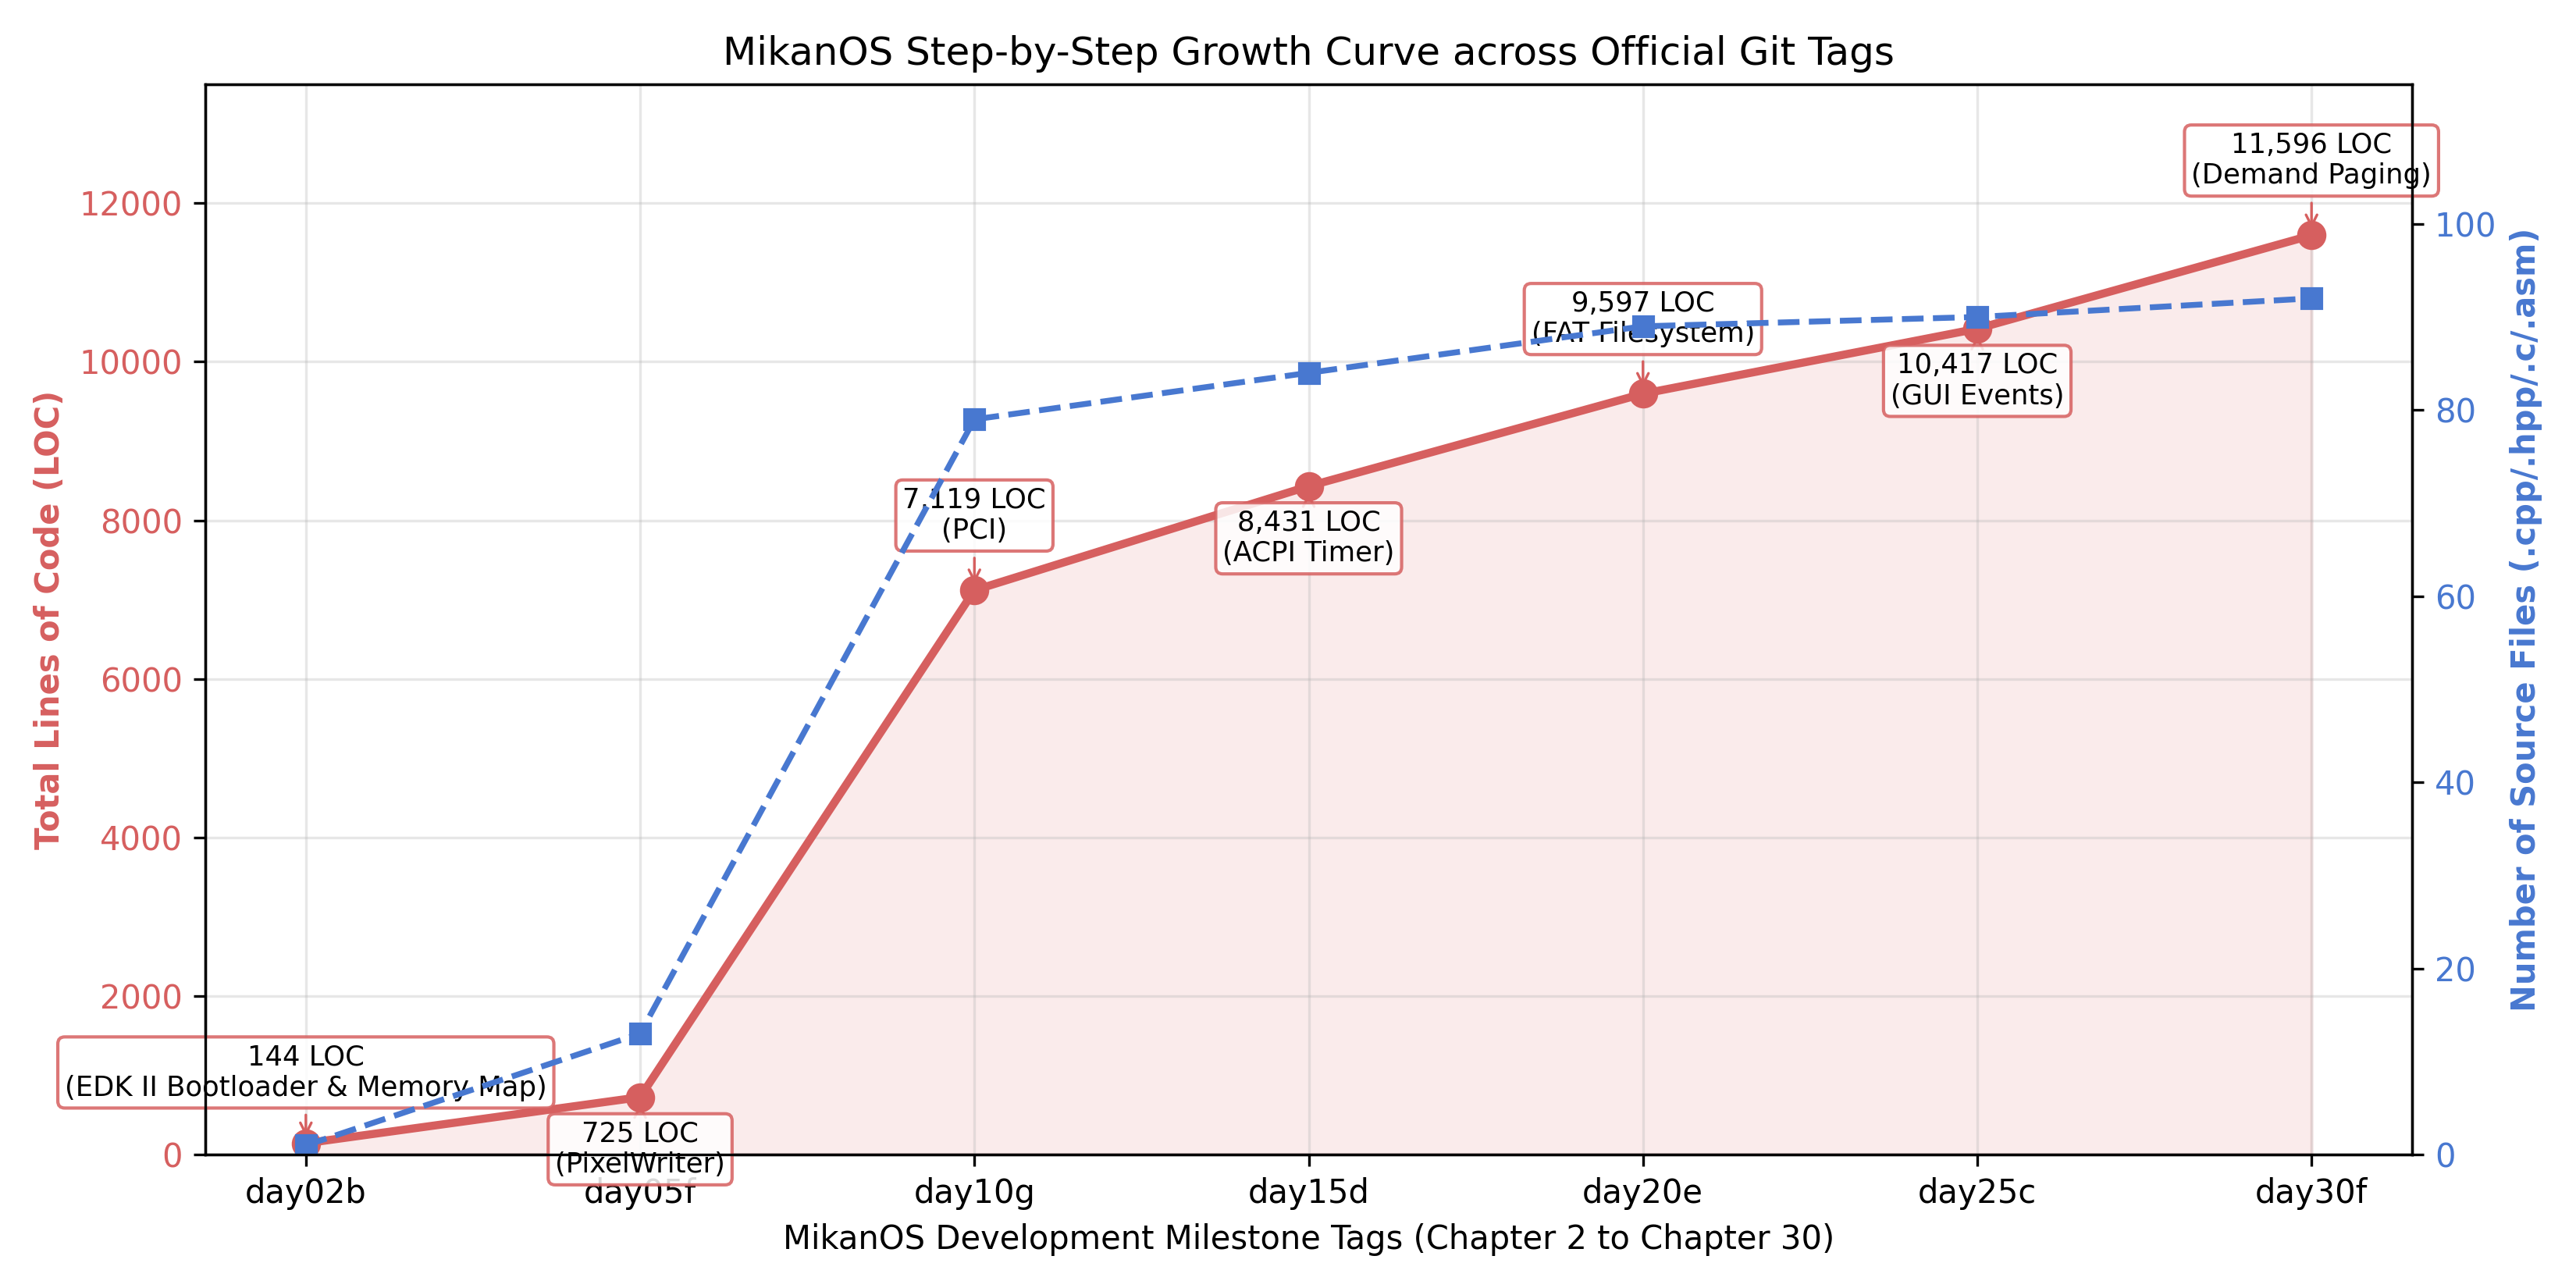

In [4]:
# 図版生成 2: MikanOS 公式Gitタグ (day02b 〜 day30f) におけるコード規模の段階的成長曲線
from common import MIKANOS_GROWTH_METRICS

tags = [item[0] for item in MIKANOS_GROWTH_METRICS]
file_counts = [item[1] for item in MIKANOS_GROWTH_METRICS]
line_counts = [item[2] for item in MIKANOS_GROWTH_METRICS]
milestones = [item[3] for item in MIKANOS_GROWTH_METRICS]

fig, ax1 = plt.subplots(figsize=(11, 5.5))

color_loc = "#D65F5F"
ax1.plot(tags, line_counts, marker="o", linewidth=2.5, markersize=8, color=color_loc, label="Kernel + Loader LOC")
ax1.fill_between(tags, line_counts, color=color_loc, alpha=0.12)
ax1.set_xlabel("MikanOS Development Milestone Tags (Chapter 2 to Chapter 30)")
ax1.set_ylabel("Total Lines of Code (LOC)", color=color_loc, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_loc)
ax1.set_ylim(0, 13_500)

for i, (tag, loc, ms) in enumerate(zip(tags, line_counts, milestones)):
    offset_y = 650 if i % 2 == 0 else -950
    if i == 0:
        offset_y = 600
    ax1.annotate(
        f"{loc:,} LOC\n({ms.split(',')[0]})",
        xy=(i, loc),
        xytext=(i, loc + offset_y),
        ha="center",
        fontsize=8.5,
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=color_loc, alpha=0.85),
        arrowprops=dict(arrowstyle="->", color=color_loc, lw=0.8),
    )

ax2 = ax1.twinx()
color_files = "#4878D0"
ax2.plot(tags, file_counts, marker="s", linestyle="--", linewidth=1.8, markersize=6, color=color_files, label="Source File Count")
ax2.set_ylabel("Number of Source Files (.cpp/.hpp/.c/.asm)", color=color_files, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_files)
ax2.grid(False)
ax2.set_ylim(0, 115)

plt.title("MikanOS Step-by-Step Growth Curve across Official Git Tags")
fig.tight_layout()

out_fig2 = result_dir / "fig0_2_mikanos_growth_curve.png"
fig.savefig(out_fig2, dpi=300)
plt.close(fig)

display(Image(filename=str(out_fig2)))


---

## 2. まとめと次節への橋渡し

- **商用OSとの違い**: 現代の Linux（約2,100万行）を個人で作ることはできないが、初期の Linux 0.01（10,239行）や MikanOS（11,071行）の規模であれば、個人でも最初から最後まで完全に手作りできる。
- **フルスクラッチの価値**: 既存OSの改造ではなく、電源投入からアプリ実行までを全て自作することで、PC と OS のブラックボックスが完全に解明される。
- **スモールステップの原則**: 最初から完璧な理論や設計を求めず、第2章の 144行のコードから少しずつ機能を追加して動かすことで、確実に 64ビット GUI マルチタスク OS へ到達できる。

次節 **「0.2 そもそもOSって何？（含 コラム0.1: OSの仕様とPOSIX）」** では、OS が持つ3つの本質的役割（ハードウェア制御・資源管理・抽象化インターフェース）と POSIX 規格の意味を掘り下げます。
